# What Are Outliers?
Outliers are extreme values that lie far outside the normal range of the dataset. They distort distance-based models (KNN, KMeans) and linear models (Linear/Logistic Regression).

1. Trimming (Removing Data)
- What it does: Completely drops the rows containing outlier values from the dataset.
- When to use: Large datasets where removing a few rows won't impact overall sample size.
- Drawback: Risk of losing valuable information.
2. Capping (Setting Limits)
- What it does: Replaces extreme values with a fixed Upper or Lower threshold instead of deleting them.
- When to use: Small to medium datasets where losing rows is not an option.
- Logic:
- - Values above Upper Limit --> 
 Set to Upper Limit
- - Values below Lower Limit -->
 Set to Lower Limit
#Summary Rule
- Large Data 
 Trim (Quick and clean).
- Small/Medium Data 
 Cap (Preserves data size).

In [ ]:
import numpy as np
import pandas as pd

In [ ]:
df = pd.read_csv("/content/newplacementdata - newplacementdata.csv")

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
df['placement_exam_marks'].describe()

,placement_exam_marks
count,1000.000000
mean,32.225000
std,19.130822
min,0.000000
25%,17.000000
50%,28.000000
75%,44.000000
max,100.000000


<Axes: xlabel='placement_exam_marks'>

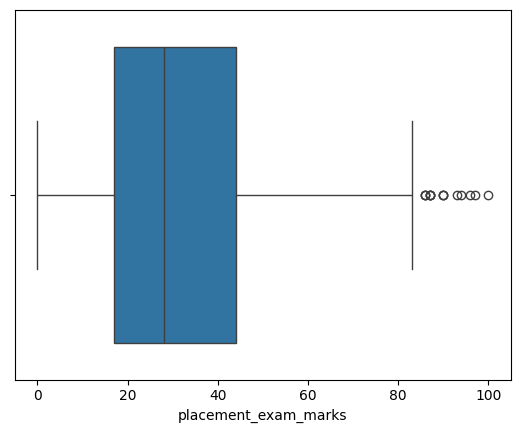

In [ ]:
sns.boxplot(x=df['placement_exam_marks'])

In [ ]:
# finding the IQR

percentile25 = df['placement_exam_marks'].quantile(0.25)
percentile75 = df['placement_exam_marks'].quantile(0.75)

In [ ]:
percentile25

np.float64(17.0)

In [ ]:
percentile75

np.float64(44.0)

In [ ]:
IQR = percentile75 - percentile25
IQR

np.float64(27.0)

In [ ]:
upper_limit = percentile75 + 1.5 * IQR
lower_limit = percentile25 - 1.5 * IQR

In [ ]:
upper_limit

np.float64(84.5)

In [ ]:
lower_limit

np.float64(-23.5)

**Finding Our Outliers**

In [ ]:
df[df['placement_exam_marks']>upper_limit]

,cgpa,placement_exam_marks,placed
9,7.75,94,1
40,6.60,86,1
61,7.51,86,0
134,6.33,93,0
162,7.80,90,0
283,7.09,87,0
290,8.38,87,0
311,6.97,87,1
324,6.64,90,0
630,6.56,96,1


In [ ]:
df[df['placement_exam_marks']<lower_limit]

,cgpa,placement_exam_marks,placed


In [ ]:
# trimming ---> 4(lower).....1, uppper(25).....(50) ----> here 1, 50 are outliers ---> lower(4) <--- upper(25) mid data.

# capping ----> 4(lower)....1, upper(25)....(50) ---> capping lower point(1)
# upper point upper point(50)

In [ ]:
# Trimming (Outlier removing technique 1)

In [ ]:
newdf = df[df['placement_exam_marks']< upper_limit]

In [ ]:
# newdf

<Axes: xlabel='placement_exam_marks'>

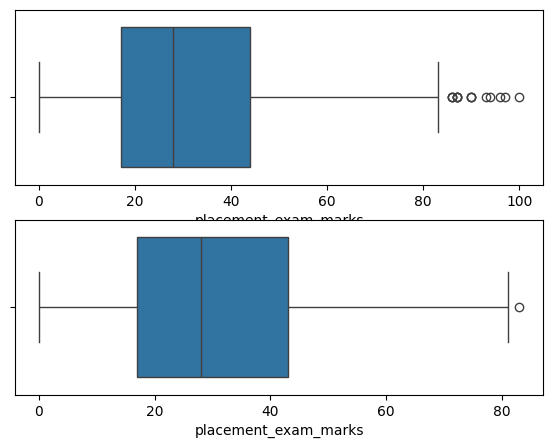

In [ ]:
plt.figure(figsize=(15,5))

plt.subplot(222)
sns.boxplot(x=df['placement_exam_marks'])

plt.subplot(224)
sns.boxplot(x=newdf['placement_exam_marks'])
#

In [ ]:
# capping(outlier removing technique 2)

In [ ]:
new_df_cap = df.copy()

In [ ]:
# min = 5, max = 15

# min 4,3,1
# max 20,30,50

# updated_min_value = 1
# updated_max_value = 50

In [ ]:
new_df_cap['placement_exam_marks'] = np.where(
    new_df_cap['placement_exam_marks']<lower_limit,
    lower_limit,
    np.where(new_df_cap['placement_exam_marks']>upper_limit,upper_limit,

    new_df_cap['placement_exam_marks']
    )
    )

In [ ]:
new_df_cap

,cgpa,placement_exam_marks,placed
0,7.19,26.0,1
1,7.46,38.0,1
2,7.54,40.0,1
3,6.42,8.0,1
4,7.23,17.0,0
...,...,...,...
995,8.87,44.0,1
996,9.12,65.0,1
997,4.89,34.0,0
998,8.62,46.0,1


In [ ]:
# comparsion

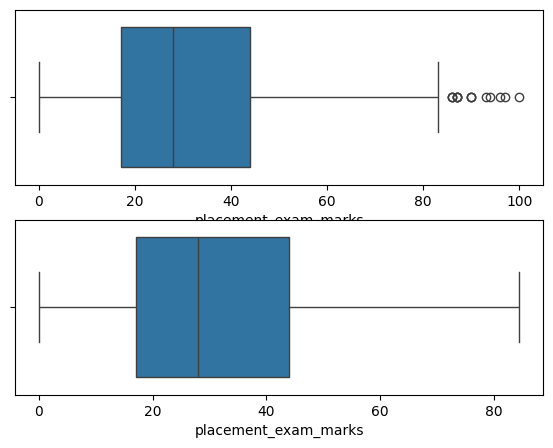

In [ ]:
plt.figure(figsize=(15,5))

plt.subplot(222)
sns.boxplot(x=df['placement_exam_marks'])

plt.subplot(224)
sns.boxplot(x=new_df_cap['placement_exam_marks'])
plt.show()

In [ ]:
df2 = pd.read_csv("/content/titanic - titanic.csv")

In [ ]:
df2.shape

(418, 12)

<Axes: xlabel='Age'>

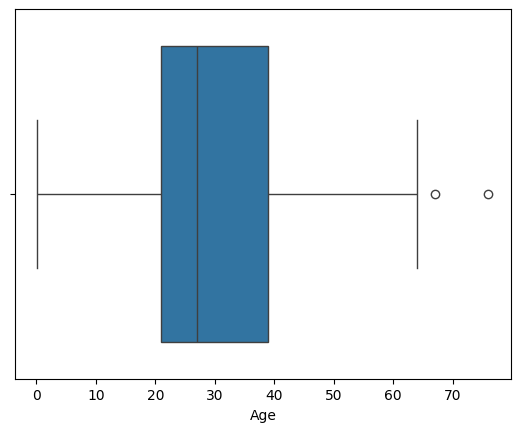

In [ ]:
sns.boxplot(x=df2['Age'])

In [ ]:
# finding the IQR
percentile251 = df2['Age'].quantile(0.25)
percentile752 = df2['Age'].quantile(0.75)

In [ ]:
percentile251

np.float64(21.0)

In [ ]:
percentile752

np.float64(39.0)

In [ ]:
IQR = percentile752 - percentile251
IQR

np.float64(18.0)

In [ ]:
upper_limit1 = percentile752 + 1.5 * IQR
lower_limit1 = percentile251 - 1.5 * IQR

In [ ]:
upper_limit1

np.float64(66.0)

In [ ]:
lower_limit1

np.float64(-6.0)

 **Finding our outlier**

In [ ]:
df2[df2['Age']>upper_limit1]

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
81,973,0,1,"Straus, Mr. Isidor",male,67.0,1,0,PC 17483,221.7792,C55 C57,S
96,988,1,1,"Cavendish, Mrs. Tyrell William (Julia Florence...",female,76.0,1,0,19877,78.8500,C46,S


In [ ]:
df2[df2['Age']<lower_limit1]

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked


In [ ]:
newdf2 = df2[df2['Age']<upper_limit1]

In [ ]:
# trimming

<Axes: xlabel='Age'>

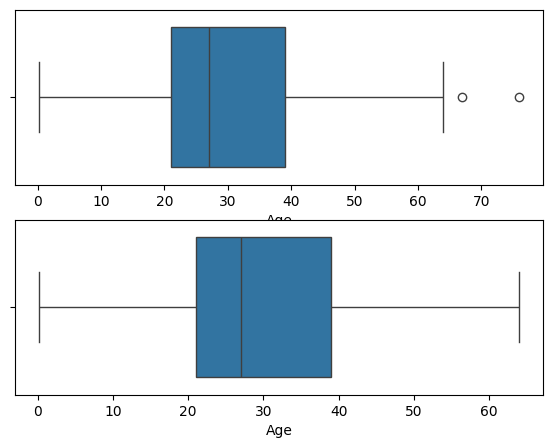

In [ ]:
plt.figure(figsize=(15,5))

plt.subplot(222)
sns.boxplot(x=df2['Age'])

plt.subplot(224)
sns.boxplot(x=newdf2['Age'])

In [ ]:
# capping

In [ ]:
new_df_cap2 = df2.copy()

In [ ]:
new_df_cap2['Age'] = np.where(
    new_df_cap2['Age']<lower_limit,
    lower_limit,
    np.where(new_df_cap2['Age']>upper_limit,upper_limit,

    new_df_cap2['Age']
    )
    )

In [ ]:
new_df_cap2

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,892,0,3,"Kelly, Mr. James",male,34.5,0,0,330911,7.8292,NaN,Q
1,893,1,3,"Wilkes, Mrs. James (Ellen Needs)",female,47.0,1,0,363272,7.0000,NaN,S
2,894,0,2,"Myles, Mr. Thomas Francis",male,62.0,0,0,240276,9.6875,NaN,Q
3,895,0,3,"Wirz, Mr. Albert",male,27.0,0,0,315154,8.6625,NaN,S
4,896,1,3,"Hirvonen, Mrs. Alexander (Helga E Lindqvist)",female,22.0,1,1,3101298,12.2875,NaN,S
...,...,...,...,...,...,...,...,...,...,...,...,...
413,1305,0,3,"Spector, Mr. Woolf",male,NaN,0,0,A.5. 3236,8.0500,NaN,S
414,1306,1,1,"Oliva y Ocana, Dona. Fermina",female,39.0,0,0,PC 17758,108.9000,C105,C
415,1307,0,3,"Saether, Mr. Simon Sivertsen",male,38.5,0,0,SOTON/O.Q. 3101262,7.2500,NaN,S
416,1308,0,3,"Ware, Mr. Frederick",male,NaN,0,0,359309,8.0500,NaN,S


In [ ]:
# comparsion

<Axes: xlabel='Age'>

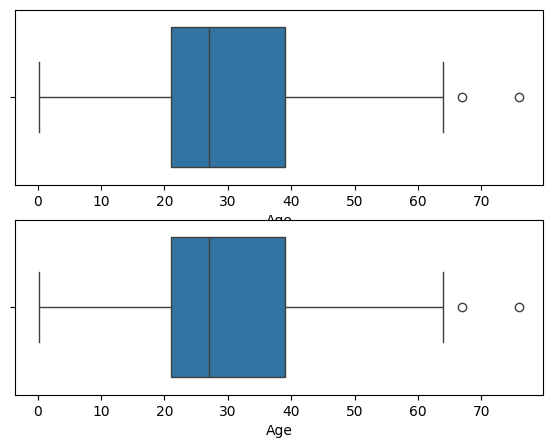

In [ ]:
plt.figure(figsize=(15,5))

plt.subplot(222)
sns.boxplot(x=df2['Age'])

plt.subplot(224)
sns.boxplot(x=new_df_cap2['Age'])